In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


In [19]:
df = pd.read_csv("../data_folder/data.csv")
diseases = pd.read_csv("../data_folder/labels.csv")

In [20]:
main_df = pd.merge(df,diseases,on="Unnamed: 0")
main_df.rename(columns={'Unnamed: 0':'Samples'}, inplace=True)
main_df.head()

,Samples,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,...,gene_20522,gene_20523,gene_20524,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530,Class
0,sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871,0.0,...,8.210257,9.723516,7.220030,9.119813,12.003135,9.650743,8.921326,5.286759,0.0,PRAD
1,sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000,0.0,...,7.323865,9.740931,6.256586,8.381612,12.674552,10.517059,9.397854,2.094168,0.0,LUAD
2,sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595,0.0,...,8.127123,10.908640,5.401607,9.911597,9.045255,9.788359,10.090470,1.683023,0.0,PRAD
3,sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882,0.0,...,8.792959,10.141520,8.942805,9.601208,11.392682,9.694814,9.684365,3.292001,0.0,PRAD
4,sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982,0.0,...,8.891425,10.373790,7.181162,9.846910,11.922439,9.217749,9.461191,5.110372,0.0,BRCA


In [21]:
X = main_df.drop(["Class","Samples"],axis=1)
Y = main_df["Class"]
model_1 = make_pipeline(StandardScaler(),LogisticRegression())
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,stratify=Y,random_state=42)
model_1.fit(X_train,Y_train)
predictions_1 = model_1.predict(X_test)
accuracy_1 = accuracy_score(Y_test,predictions_1)

In [22]:
model_1.named_steps["logisticregression"].n_iter_

array([9], dtype=int32)

In [23]:
cross_1 = cross_val_score(model_1, X, Y, cv=5)
cross_1

array([0.99378882, 1.        , 0.99375   , 0.99375   , 0.99375   ])

In [24]:
print(cross_1.mean())

0.9950077639751553


In [25]:
coefs = np.array(model_1.named_steps["logisticregression"].coef_)
abs_coef = abs(coefs)
importance_scores_1 = np.mean(abs_coef,axis=0)

In [26]:
gene_importance_df_1 = pd.DataFrame({"Gene":X.columns,"Importance":importance_scores_1})
gene_importance_df_1.sort_values(by="Importance",ascending=False,inplace=True)
genes_to_remove_1 = gene_importance_df_1.head(len(gene_importance_df_1)//10)["Gene"]

In [27]:
X_reduced = X.drop(genes_to_remove_1,axis = 1)
model_2 = LogisticRegression()
cross_2 = cross_val_score(model_2,X_reduced,Y,cv=5)

In [28]:
X_reduced[0:5]

,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,...,gene_20519,gene_20521,gene_20522,gene_20523,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530
0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871,0.0,0.0,...,7.475709,4.926711,8.210257,9.723516,9.119813,12.003135,9.650743,8.921326,5.286759,0.0
1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000,0.0,0.0,...,9.190867,4.593372,7.323865,9.740931,8.381612,12.674552,10.517059,9.397854,2.094168,0.0
2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595,0.0,0.0,...,9.036654,5.125213,8.127123,10.908640,9.911597,9.045255,9.788359,10.090470,1.683023,0.0
3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882,0.0,0.0,...,8.665592,6.076566,8.792959,10.141520,9.601208,11.392682,9.694814,9.684365,3.292001,0.0
4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982,0.0,0.0,...,8.233366,5.996032,8.891425,10.373790,9.846910,11.922439,9.217749,9.461191,5.110372,0.0


In [29]:
total_col =len(X.columns)

In [30]:
def gene_removal(x,y,percent,limit):
    complete = False
    initial_genes = len(x.columns)
    iter = 0


    while not complete:
        model = make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
        model.fit(x,y)
        cross = cross_val_score(model,x,y,cv=5)
        cross_mean = cross.mean()
        cross_std = cross.std()

        if iter == 0:
            data = pd.DataFrame({"Gene count":[initial_genes],"Cross validation score":[cross_mean],"Standard deviation":[cross_std]})
        else:
            genes = len(x.columns)
            data.loc[len(data)] = [genes,cross_mean,cross_std]
        if len(x.columns)<=limit:
            complete = True
        else:
            np_coefs = np.array(model.named_steps["logisticregression"].coef_)
            importance_scores = np.mean(abs(np_coefs),axis=0)
            gene_importance_df = pd.DataFrame({"Gene":x.columns,"Importance":importance_scores})
            gene_importance_df.sort_values(by="Importance",ascending=False,inplace=True)
            genes_to_remove = gene_importance_df.head(round(len(x.columns)*percent))["Gene"]
            x=x.drop(genes_to_remove,axis=1)
        iter+=1
    return data



In [31]:
data = gene_removal(X,Y,0.5,total_col//40)

In [32]:
data

,Gene count,Cross validation score,Standard deviation
0,20531.0,0.995008,0.002496
1,10265.0,0.992516,0.006111
2,5133.0,0.986266,0.007291
3,2567.0,0.897609,0.011734
4,1283.0,0.680427,0.014868
5,641.0,0.420699,0.018994
6,321.0,0.370784,0.014487


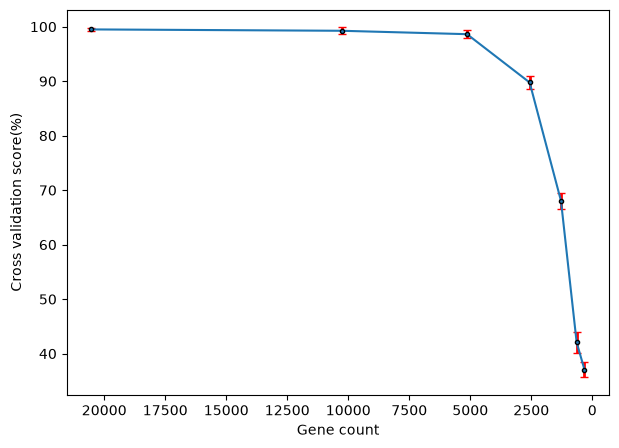

In [33]:
plt.figure(figsize=(7,5))
plt.errorbar(data["Gene count"],
             data["Cross validation score"] * 100,
             marker=".",markeredgecolor="black",
             yerr=data["Standard deviation"]*100,ecolor="red",elinewidth=2,capsize=3)
plt.xlabel("Gene count")
plt.ylabel("Cross validation score(%)")
plt.gca().invert_xaxis()
plt.savefig("../notes/gene_removal.png",dpi=300,bbox_inches="tight")
plt.show()